In [3]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Наложение и удаление шума

In [6]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

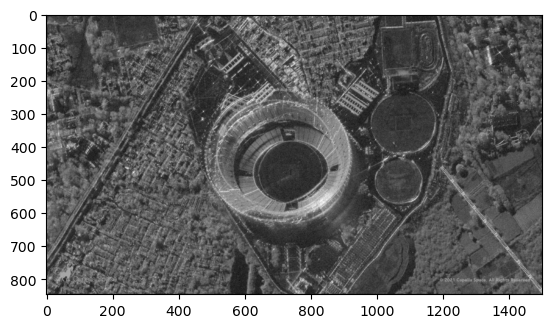

In [8]:
plt.imshow(image_gray, cmap="gray")

In [12]:
# Gaussian noise
mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

array([[  0,  16,   0, ...,   0,   0,   0],
       [ 44,   0,   4, ..., 180,  27, 149],
       [ 41,   0,   0, ...,  84,   0, 107],
       ...,
       [  0,   0,   0, ...,   0,   0,  40],
       [  0,   0,   6, ...,   0, 238,   0],
       [  0,   0,   6, ..., 123,  42,   0]],
      shape=(846, 1500), dtype=uint8)

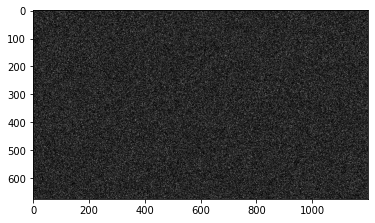

In [82]:
plt.imshow(noise_gauss, cmap="gray")

In [13]:
# Salt and pepper
noise =  np.random.randint(0, 101, size = (image_gray.shape[0], image_gray.shape[1]), dtype=int)
zeros_pixel = np.where(noise == 0)
ones_pixel = np.where(noise == 100)

In [14]:
bg_image = np.ones(image_gray.shape, np.uint8) * 128

In [15]:
bg_image[zeros_pixel] = 0
bg_image[ones_pixel] = 255

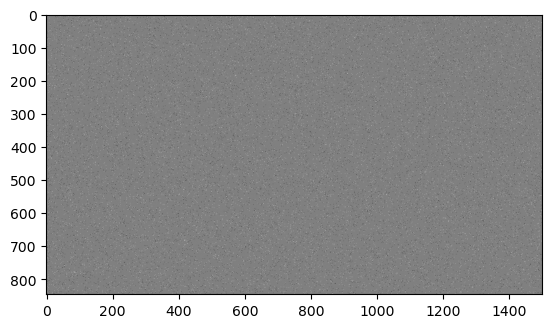

In [16]:
plt.imshow(bg_image, cmap="gray")

In [17]:
image_noise_gauss = cv2.add(image_gray,noise_gauss)

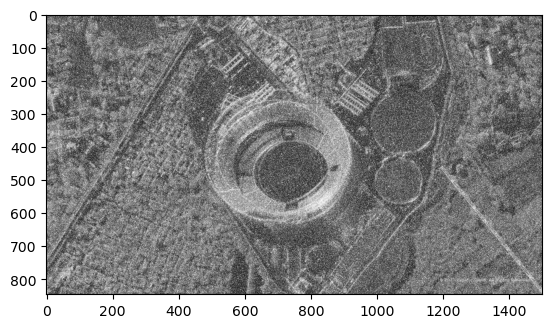

In [18]:
plt.imshow(image_noise_gauss, cmap="gray")

In [19]:
from skimage.metrics import structural_similarity, mean_squared_error
mse_gauss = mean_squared_error(image_gray, image_noise_gauss)
(ssim, diff) = structural_similarity(image_gray, image_noise_gauss, full=True)
print(mse_gauss, ssim)

4251.311275019701 0.12882014124890243


In [20]:
image_gauss_median = cv2.medianBlur(image_noise_gauss, 3)

In [21]:
mse_gauss_median = mean_squared_error(image_gray, image_gauss_median)
(ssim_gauss_median, diff) = structural_similarity(image_gray,  image_gauss_median, full=True)

In [22]:
print(mse_gauss_median, ssim_gauss_median)

902.3204846335698 0.4131549446627671


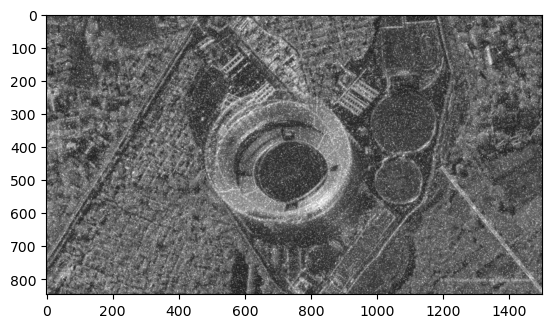

In [23]:
plt.imshow(image_gauss_median, cmap="gray")

In [24]:
import copy

image_sp = copy.deepcopy(image_gray)

image_sp[zeros_pixel] = 0
image_sp[ones_pixel] = 255

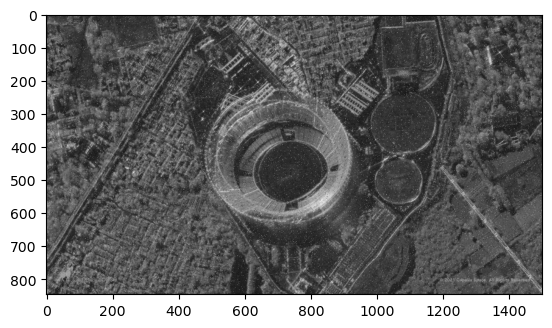

In [25]:
plt.imshow(image_sp, cmap="gray")

In [32]:
mse_sp = mean_squared_error(image_gray, image_sp)
(ssim_sp, diff) = structural_similarity(image_gray, image_sp, full=True)
print(mse_sp, ssim_sp)

386.7862828999212 0.6628108574862959


In [33]:
image_sp_median = cv2.medianBlur(image_sp, 3)

In [34]:
mse_sp_median = mean_squared_error(image_gray, image_sp_median)
(ssim_sp_median, diff) = structural_similarity(image_gray, image_sp_median, full=True)
print(mse_sp_median, ssim_sp_median)

16.45093853427896 0.9538915269739848


# Другие типы фильтров

In [36]:
image_gauss_gauss = cv2.GaussianBlur(image_noise_gauss,(5,5),0)

In [37]:
image_gauss_bilat = cv2.bilateralFilter(image_noise_gauss,9,75,75)

In [38]:
image_gauss_nlm = cv2.fastNlMeansDenoising(image_noise_gauss, h = 20)

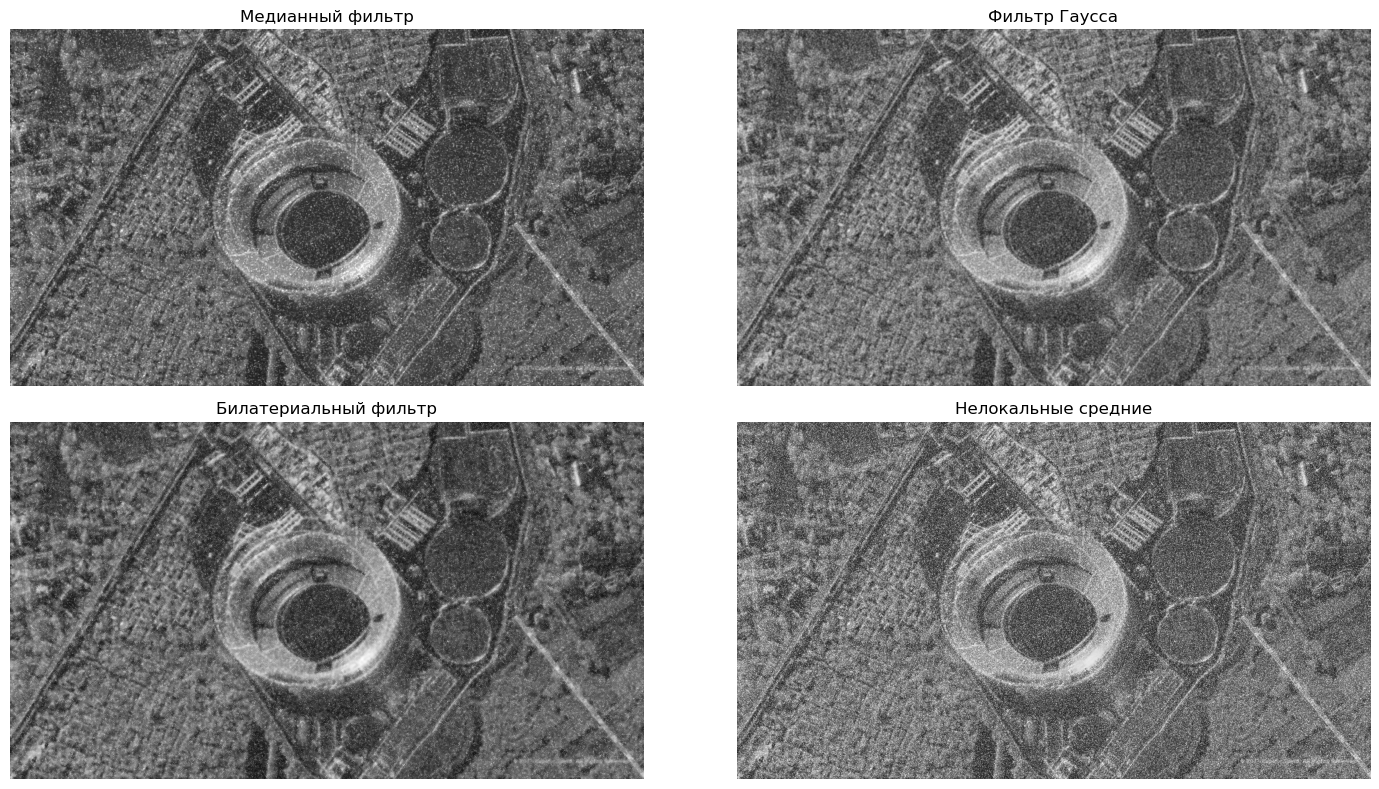

In [40]:
# Ррезультаты фильтрации гауссовского шумам для визульного сравнения

plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.imshow(image_gauss_median, cmap="gray")
plt.title("Медианный фильтр")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(image_gauss_gauss, cmap="gray")
plt.title("Фильтр Гаусса")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(image_gauss_bilat, cmap="gray")
plt.title("Билатериальный фильтр")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(image_gauss_nlm, cmap="gray")
plt.title("Нелокальные средние")
plt.axis("off")

plt.tight_layout()
plt.show()

In [41]:
# Оценка качества фильтрации

results = {
    "Медианный": image_gauss_median,
    "Гаусса": image_gauss_gauss,
    "Билатериальный": image_gauss_bilat,
    "Нелокальных средних": image_gauss_nlm
}

for name, result in results.items():
    mse = mean_squared_error(image_gray, result)
    ssim = structural_similarity(
        image_gray, result, data_range=255
    )

    print(f"{name}: MSE = {mse:.2f}, SSIM = {ssim:.4f}")

Медианный: MSE = 902.32, SSIM = 0.4132
Гаусса: MSE = 1688.19, SSIM = 0.5042
Билатериальный: MSE = 1757.26, SSIM = 0.2819
Нелокальных средних: MSE = 4244.66, SSIM = 0.1296


In [ ]:
# Вывод: 

# Для оценки качества фильтрации я использовала метрики MSE и SSIM.
# Наименьшее значение MSE показал медианный фильтр (902.32).
# Наибольшее значение SSIM получил фильтр Гаусса (0.5042).

# Исходя из результатов сравнения фильтрации шума, медианный фильтр показал лучший результат среднеквадратичной ошибки(наименьший), 
# а гауссовский фильтр показал наилучшее структурное сходство с исходным изображением.



In [147]:
import math

def geom(a):
    prod = 1
    for i in range(a.shape[0]):
        prod1 = 1
        for j in range(a.shape[1]):
            prod1 *= a[i,j]
        prod1 = math.pow(prod1, 1.0/9.0)
        prod *= prod1
    return prod

def proc(img, filter):
    img_res = copy.deepcopy(img)
    for i in range(0,img.shape[0] -2):
        for j in range(0,img.shape[1] -2):
            img_res[i:i+3, j:j+3] = filter(img[i:i+3, j:j+3])
    return img_res
    
res = proc(image_noise_gauss, geom)


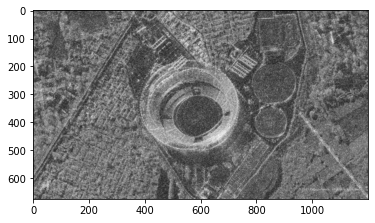

In [148]:
plt.imshow(res, cmap="gray")

In [149]:
mse_geom = mean_squared_error(image_gray, res)
(ssim_geom, diff) = structural_similarity(image_gray, res, full=True)
print(mse_geom, ssim_geom)

1219.7879691358025 0.3984170557811386



# 2D свертка

In [105]:
# averaging filter
kernel_5 = np.ones((5,5),np.float32)/25
image_k5 = cv2.filter2D(image_gray,-1,kernel_5)
# blured_image = cv2.blur(img,(5,5))
image_b5 = cv2.blur(image_gray,(5,5))

In [106]:
mse_kb = mean_squared_error(image_k5, image_b5)
(ssim_kb, diff) = structural_similarity(image_k5, image_b5, full=True)
print(mse_kb, ssim_kb)

0.0 1.0


In [127]:
# Laplasian
kernel_lapl = np.array([[0,-10,0],
                        [-10,40,-10],
                        [0,-10,0]], np.float32)

In [128]:
image_lapl = cv2.filter2D(image_gray,-1,kernel_lapl) 

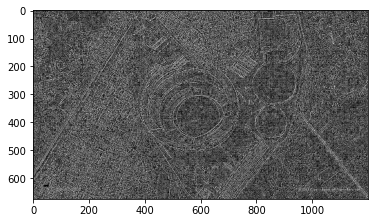

In [129]:
plt.imshow(image_lapl, cmap="gray")

In [ ]:
# ДЗ 2
# Зашумить изображение при помощи шума гаусса, постоянного шума.
# Протестировать медианный фильтр, фильтр гаусса, билатериальный фильтр, фильтр нелокальных средних с различными параметрами.
# Выяснить, какой фильтр показал лучший результат фильтрации шума.